# GMM Clean Source Sanity Check

This notebook checks the first clean end-to-end path:

1. Build a small GMM config.
2. Load train and reference tensors.
3. Plot the known intrinsic space.
4. Build the GDFM + MLP model.
5. Run a short training loop.
6. Sample with Heun.
7. Compute nearest-neighbor and GMM metrics.

The goal is not a good model. The goal is to prove that clean source code can run from config to metrics.

## 1. Import the clean source

This cell finds the clean repo root, adds it to `sys.path`, and imports only the modules used in this notebook.

In [14]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import torch

# Find the repo root from the current working directory.
cwd = Path.cwd().resolve()
for candidate in (cwd, *cwd.parents):
    if (candidate / "mem_param_src").is_dir():
        REPO_ROOT = candidate
        break
else:
    # Fallback for running this notebook from another directory.
    REPO_ROOT = Path(
        "/Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_param_clean"
    )

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from mem_param_src import GDFM, get_base_config
from mem_param_src.datasets import build_data_bundle
from mem_param_src.metrics import compute_memorization_metrics, compute_nn_stats
from mem_param_src.metrics.synthetic import gmm_intrinsic_metrics, project_to_subspace

plt.rcParams["figure.figsize"] = (9, 6)
plt.rcParams["axes.grid"] = True

torch.manual_seed(7)
print(f"repo root: {REPO_ROOT}")
print(f"torch: {torch.__version__}")

repo root: /Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_param_clean
torch: 2.9.1


## 2. Build a tiny GMM config

We use a small ambient dimension and a two-dimensional intrinsic subspace. This makes plots easy to read.

In [30]:
cfg = get_base_config()

# Study identity.
cfg.study.name = "gmm_clean_smoke"
cfg.study.dataset_key = "gmm_subspace"
cfg.outputs.run_name = "gmm_clean_smoke"

# Framework: common velocity loss for the first smoke test.
cfg.framework.family = "fm"
cfg.framework.prediction_space = "x"
cfg.framework.loss_space = "x"
cfg.framework.loss_weighting = "unit"

# Tiny synthetic data.
cfg.data.dataset = "gmm_subspace"
cfg.data.root = "synthetic"
cfg.data.n_train = 5
cfg.data.n_test = 256
cfg.data.data_dim = 2
cfg.data.ambient_dim = 2
cfg.data.intrinsic_dim = 2
cfg.data.n_clusters = 3
cfg.data.sigma_z = 0.805
cfg.data.sigma_eta = 1.0e-4
cfg.data.geometry_seed = 24

# Small MLP.
cfg.network.arch = "mlp"
cfg.network.hidden_dim = 128
cfg.network.n_layers = 3
cfg.network.time_emb_dim = 64

# Short CPU run.
cfg.training.seed = 7
cfg.training.batch_cap = 64
cfg.training.batch_size = 64
cfg.training.lr = 1.0e-3
cfg.training.weight_decay = 0.0
cfg.training.n_training_steps = 10000
cfg.training.start_time = 0.01
cfg.training.end_time = 0.99
cfg.training.use_safe_division = True
cfg.training.denominator_epsilon = 0.01

# Fast sampler and metrics.
cfg.sampling.method = "heun"
cfg.sampling.n_steps = 50
cfg.sampling.start_time = 0.01
cfg.sampling.end_time = 0.99
cfg.sampling.use_safe_division = True
cfg.sampling.denominator_epsilon = 0.01
cfg.sampling.output = "final_sample"
cfg.evaluation.n_samples = 128
cfg.evaluation.sample_bank_size = 128
cfg.evaluation.ratio_threshold = 0.3
cfg.evaluation.chunk_size = 256

for key, value in {
    "dataset": cfg.data.dataset,
    "train/reference": f"{cfg.data.n_train}/{cfg.data.n_test}",
    "ambient_dim": cfg.data.data_dim,
    "intrinsic_dim": cfg.data.intrinsic_dim,
    "clusters": cfg.data.n_clusters,
    "prediction/loss": f"{cfg.framework.prediction_space}/{cfg.framework.loss_space}",
    "training_steps": cfg.training.n_training_steps,
    "training_time": f"{cfg.training.start_time} -> {cfg.training.end_time}",
    "training_safe_division": cfg.training.use_safe_division,
    "sampler": f"{cfg.sampling.method}, {cfg.sampling.n_steps} steps",
    "sampling_time": f"{cfg.sampling.start_time} -> {cfg.sampling.end_time}",
    "sampling_safe_division": cfg.sampling.use_safe_division,
    "sampling_output": cfg.sampling.output,
}.items():
    print(f"{key:16s}: {value}")

dataset         : gmm_subspace
train/reference : 5/256
ambient_dim     : 2
intrinsic_dim   : 2
clusters        : 3
prediction/loss : x/x
training_steps  : 10000
sampler         : heun, 50 steps


## 3. Load the synthetic data bundle

The data loader returns the train tensor, the held-out reference tensor, and the known GMM geometry.

In [31]:
bundle = build_data_bundle(cfg)
train = bundle["train"].float()
reference = bundle["reference"].float()
geometry = bundle["geometry"]
basis = geometry["basis"].float()
means = geometry["means"].float()

train_intrinsic = project_to_subspace(train, basis)["intrinsic"]
reference_intrinsic = project_to_subspace(reference, basis)["intrinsic"]

print("bundle keys:", sorted(bundle.keys()))
print("train shape:", tuple(train.shape))
print("reference shape:", tuple(reference.shape))
print("basis shape:", tuple(basis.shape))
print("means shape:", tuple(means.shape))
print("data validation:", bundle.get("data_validation"))

bundle keys: ['data_validation', 'display_shape', 'geometry', 'reference', 'reference_labels', 'reference_role', 'reference_source_id', 'reference_split', 'train', 'train_labels', 'train_role', 'train_source_id', 'train_split']
train shape: (5, 2)
reference shape: (256, 2)
basis shape: (2, 2)
means shape: (3, 2)
data validation: {'train_source_id': 'gmm_subspace:seed:7', 'reference_source_id': 'gmm_subspace:seed:8', 'train_role': 'train', 'reference_role': 'heldout_reference', 'same_source': False, 'same_source_allowed': False, 'overlap_checked': False, 'overlap_count': None}


## 4. Plot the known intrinsic data space

The GMM lives in a two-dimensional intrinsic space. The model trains on the eight-dimensional ambient vectors.

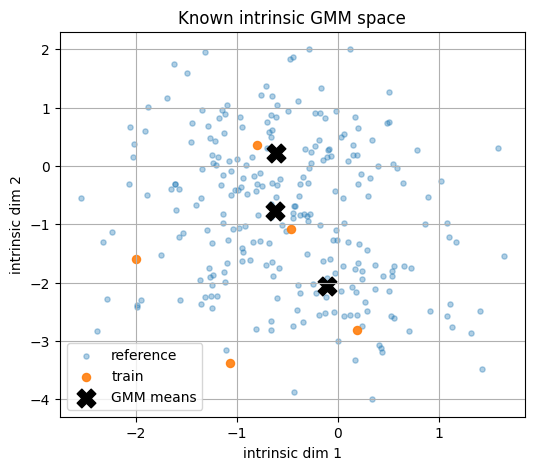

In [32]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(
    reference_intrinsic[:, 0],
    reference_intrinsic[:, 1],
    s=14,
    alpha=0.35,
    label="reference",
)
ax.scatter(train_intrinsic[:, 0], train_intrinsic[:, 1], s=34, alpha=0.9, label="train")
ax.scatter(means[:, 0], means[:, 1], s=180, marker="X", c="black", label="GMM means")
ax.set_title("Known intrinsic GMM space")
ax.set_xlabel("intrinsic dim 1")
ax.set_ylabel("intrinsic dim 2")
ax.legend(loc="best")
plt.show()

## 5. Inspect the ambient tensors

This heatmap shows the actual eight-dimensional vectors that the model sees.

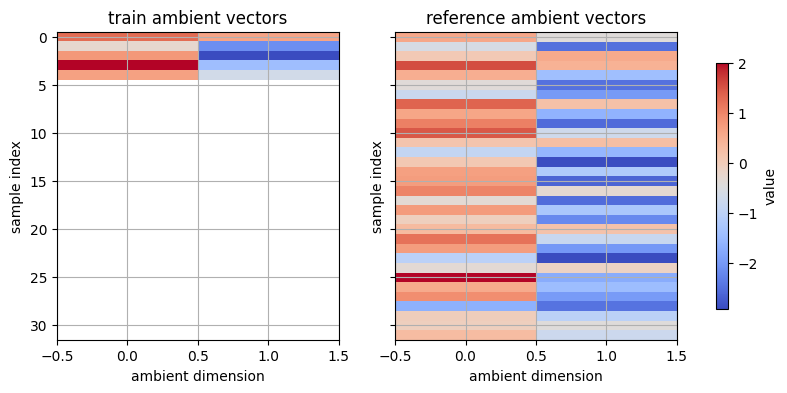

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, tensor, title in zip(
    axes, [train[:32], reference[:32]], ["train", "reference"]
):
    image = ax.imshow(tensor, aspect="auto", cmap="coolwarm")
    ax.set_title(f"{title} ambient vectors")
    ax.set_xlabel("ambient dimension")
    ax.set_ylabel("sample index")
fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.8, label="value")
plt.show()

## 6. Build the model and check one loss value

This checks that config, network construction, path conversion, and loss computation agree.

In [34]:
device = torch.device("cpu")

model = GDFM(cfg).to(device)  # build model

# optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=float(cfg.training.lr),
    weight_decay=float(cfg.training.weight_decay),
)

with torch.no_grad():
    first_loss = model.compute_loss(train[: cfg.training.batch_size].to(device)).item()

n_params = sum(p.numel() for p in model.parameters())
print(f"parameters: {n_params:,}")
print(f"first loss: {first_loss:.6f}")
print(f"prediction/loss: {model.prediction_space}/{model.loss_space}")

parameters: 50,178
first loss: 3.051555
prediction/loss: x/x


## 7. Sample before training

This gives a baseline. The untrained model should not match the GMM well.

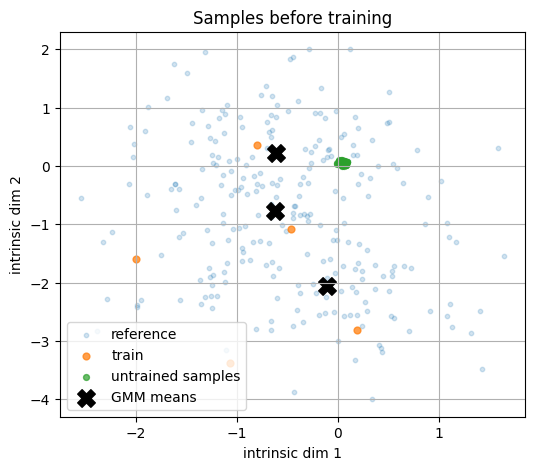

In [35]:
generator = torch.Generator().manual_seed(123)
z_eval = torch.randn(
    int(cfg.evaluation.n_samples), int(cfg.data.data_dim), generator=generator
)

with torch.no_grad():
    samples_before = model.sample(
        z_eval,
        n_steps=int(cfg.sampling.n_steps),
        method=str(cfg.sampling.method),
        start_time=float(cfg.sampling.start_time),
        end_time=float(cfg.sampling.end_time),
        use_safe_division=bool(cfg.sampling.use_safe_division),
        denominator_epsilon=float(cfg.sampling.denominator_epsilon),
        output=str(cfg.sampling.output),
        device=device,
    ).cpu()

before_intrinsic = project_to_subspace(samples_before, basis)["intrinsic"]

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(
    reference_intrinsic[:, 0],
    reference_intrinsic[:, 1],
    s=10,
    alpha=0.20,
    label="reference",
)
ax.scatter(
    train_intrinsic[:, 0], train_intrinsic[:, 1], s=24, alpha=0.75, label="train"
)
ax.scatter(
    before_intrinsic[:, 0],
    before_intrinsic[:, 1],
    s=18,
    alpha=0.70,
    label="untrained samples",
)
ax.scatter(means[:, 0], means[:, 1], s=160, marker="X", c="black", label="GMM means")
ax.set_title("Samples before training")
ax.set_xlabel("intrinsic dim 1")
ax.set_ylabel("intrinsic dim 2")
ax.legend(loc="best")
plt.show()

## 8. Train for a short run

This is a small smoke run. It only checks that gradients flow and loss moves.

In [36]:
10 % 3

1

step 100 loss 0.658338
step 200 loss 0.572891
step 300 loss 0.527556
step 400 loss 0.469356
step 500 loss 0.557738
step 600 loss 0.460024
step 700 loss 0.609001
step 800 loss 0.524935
step 900 loss 0.354327
step 1000 loss 0.375434
step 1100 loss 0.497869
step 1200 loss 0.579192
step 1300 loss 0.621459
step 1400 loss 0.502572
step 1500 loss 0.518000
step 1600 loss 0.521094
step 1700 loss 0.515368
step 1800 loss 0.395781
step 1900 loss 0.521357
step 2000 loss 0.544034
step 2100 loss 0.609870
step 2200 loss 0.466969
step 2300 loss 0.610814
step 2400 loss 0.577384
step 2500 loss 0.515604
step 2600 loss 0.607228
step 2700 loss 0.608491
step 2800 loss 0.545942
step 2900 loss 0.565099
step 3000 loss 0.579477
step 3100 loss 0.508878
step 3200 loss 0.627655
step 3300 loss 0.571193
step 3400 loss 0.577491
step 3500 loss 0.501096
step 3600 loss 0.522259
step 3700 loss 0.566941
step 3800 loss 0.358291
step 3900 loss 0.470937
step 4000 loss 0.676300
step 4100 loss 0.557954
step 4200 loss 0.491443
s

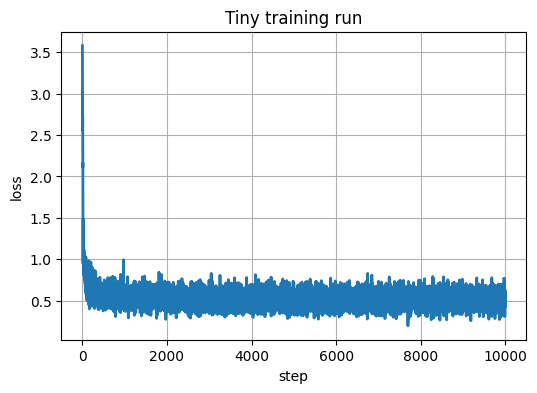

In [37]:
losses = []
train_device = train.to(device)
batch_size = int(cfg.training.batch_size)
rng = torch.Generator().manual_seed(int(cfg.training.seed))

model.train()
for step in range(1, int(cfg.training.n_training_steps) + 1):
    # Draw a random mini-batch from the fixed training tensor.
    indices = torch.randint(train_device.shape[0], (batch_size,), generator=rng)
    batch = train_device[indices]

    optimizer.zero_grad(set_to_none=True)
    loss = model.compute_loss(batch)
    loss.backward()
    optimizer.step()

    losses.append(float(loss.item()))
    if step % 100 == 0:
        print(f"step {step:3d} loss {losses[-1]:.6f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(losses, lw=2)
ax.set_title("Tiny training run")
ax.set_xlabel("step")
ax.set_ylabel("loss")
plt.show()

## 9. Sample after training

Now we reuse the same `z_eval`. This makes the before/after comparison fair.

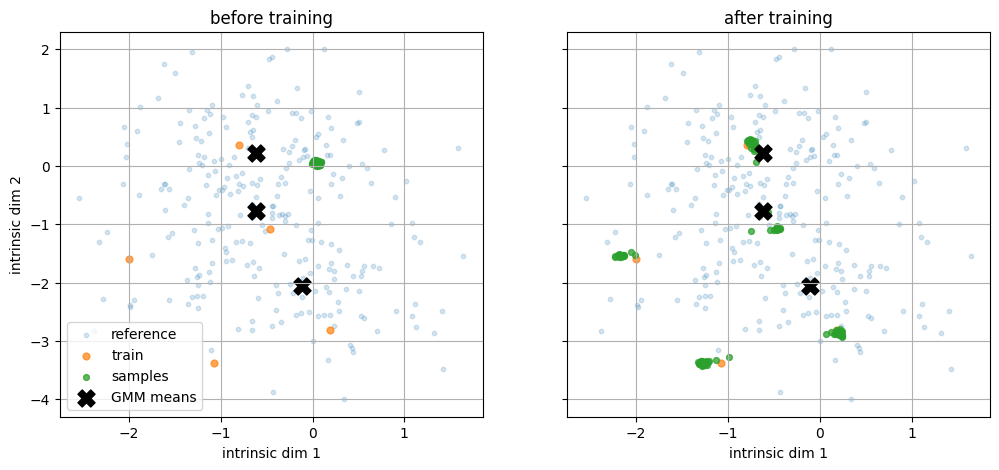

sample mean norm before: 0.0706162303686142
sample mean norm after : 2.381862163543701


In [38]:
model.eval()
with torch.no_grad():
    samples_after = model.sample(
        z_eval,
        n_steps=int(cfg.sampling.n_steps),
        method=str(cfg.sampling.method),
        start_time=float(cfg.sampling.start_time),
        end_time=float(cfg.sampling.end_time),
        use_safe_division=bool(cfg.sampling.use_safe_division),
        denominator_epsilon=float(cfg.sampling.denominator_epsilon),
        output=str(cfg.sampling.output),
        device=device,
    ).cpu()

after_intrinsic = project_to_subspace(samples_after, basis)["intrinsic"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, points, title in zip(
    axes, [before_intrinsic, after_intrinsic], ["before training", "after training"]
):
    ax.scatter(
        reference_intrinsic[:, 0],
        reference_intrinsic[:, 1],
        s=10,
        alpha=0.18,
        label="reference",
    )
    ax.scatter(
        train_intrinsic[:, 0], train_intrinsic[:, 1], s=24, alpha=0.70, label="train"
    )
    ax.scatter(points[:, 0], points[:, 1], s=18, alpha=0.75, label="samples")
    ax.scatter(
        means[:, 0], means[:, 1], s=150, marker="X", c="black", label="GMM means"
    )
    ax.set_title(title)
    ax.set_xlabel("intrinsic dim 1")
axes[0].set_ylabel("intrinsic dim 2")
axes[0].legend(loc="best")
plt.show()

print("sample mean norm before:", float(samples_before.norm(dim=1).mean()))
print("sample mean norm after :", float(samples_after.norm(dim=1).mean()))

## 10. Compute memorization and distribution metrics

Nearest-neighbor metrics are data-agnostic. GMM NLL is specific to this synthetic dataset.

In [39]:
# Ambient memorization: compare generated ambient vectors with train ambient vectors.
ambient_mem = compute_memorization_metrics(
    samples_after, train, rho=float(cfg.evaluation.ratio_threshold)
)

# Intrinsic memorization: compare generated intrinsic coordinates with train intrinsic coordinates.
intrinsic_mem = compute_memorization_metrics(
    after_intrinsic, train_intrinsic, rho=float(cfg.evaluation.ratio_threshold)
)

# Dataset-specific GMM metrics.
direction_generator = torch.Generator().manual_seed(999)
directions = torch.randn(64, int(cfg.data.intrinsic_dim), generator=direction_generator)
gmm_metrics = gmm_intrinsic_metrics(
    samples_after,
    basis,
    means,
    float(cfg.data.sigma_z),
    float(cfg.data.sigma_eta),
    reference_intrinsic,
    directions,
)

print("ambient memorization")
for key in ["rho", "f_mem", "mean_r", "median_r", "mean_d1", "mean_d2"]:
    print(
        f"  {key:10s}: {ambient_mem[key]:.6f}"
        if isinstance(ambient_mem[key], float)
        else f"  {key:10s}: {ambient_mem[key]}"
    )

print()
print("intrinsic memorization")
for key in ["rho", "f_mem", "mean_r", "median_r", "mean_d1", "mean_d2"]:
    print(
        f"  {key:10s}: {intrinsic_mem[key]:.6f}"
        if isinstance(intrinsic_mem[key], float)
        else f"  {key:10s}: {intrinsic_mem[key]}"
    )

print()
print("GMM distribution metrics")
for key, value in gmm_metrics.items():
    print(f"  {key:24s}: {value:.6f}")

ambient memorization
  rho       : 0.300000
  f_mem     : 1.000000
  mean_r    : 0.082406
  median_r  : 0.081427
  mean_d1   : 0.128029
  mean_d2   : 1.532343

intrinsic memorization
  rho       : 0.300000
  f_mem     : 1.000000
  mean_r    : 0.082407
  median_r  : 0.081421
  mean_d1   : 0.128031
  mean_d2   : 1.532343

GMM distribution metrics
  intrinsic_gmm_nll_mean  : 3.497628
  intrinsic_sliced_w2     : 1.657490


## 11. Look at nearest-neighbor links

This plot connects generated points to their nearest training points in intrinsic space.

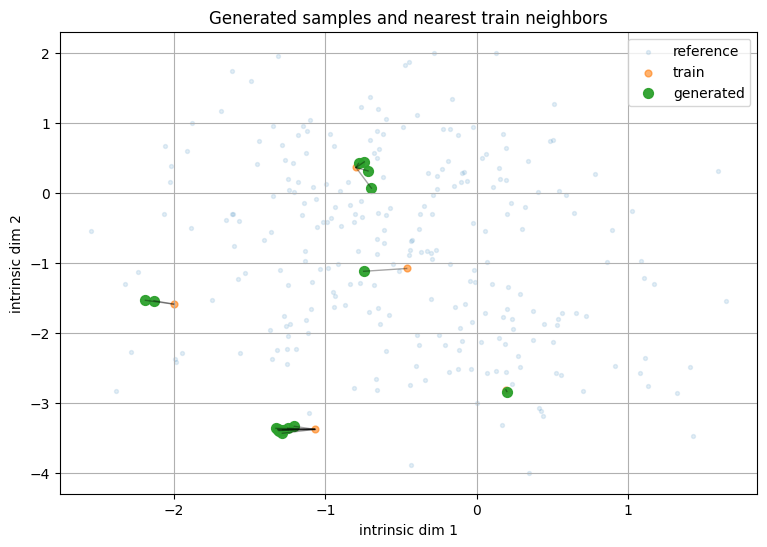

first 10 nearest-neighbor ratios:
tensor([0.0799, 0.1156, 0.2670, 0.0946, 0.1513, 0.1497, 0.0628, 0.2139, 0.1338,
        0.0662])


In [41]:
stats = compute_nn_stats(after_intrinsic, train_intrinsic)
count = 16
sample_points = after_intrinsic[:count]
neighbor_points = train_intrinsic[stats["nn_idx"][:count]]

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(
    reference_intrinsic[:, 0],
    reference_intrinsic[:, 1],
    s=8,
    alpha=0.12,
    label="reference",
)
ax.scatter(
    train_intrinsic[:, 0], train_intrinsic[:, 1], s=24, alpha=0.60, label="train"
)
ax.scatter(
    sample_points[:, 0], sample_points[:, 1], s=50, alpha=0.95, label="generated"
)
for sample_point, neighbor_point in zip(sample_points, neighbor_points):
    ax.plot(
        [sample_point[0], neighbor_point[0]],
        [sample_point[1], neighbor_point[1]],
        color="black",
        alpha=0.35,
        lw=1,
    )
ax.set_title("Generated samples and nearest train neighbors")
ax.set_xlabel("intrinsic dim 1")
ax.set_ylabel("intrinsic dim 2")
ax.legend(loc="best")
plt.show()

print("first 10 nearest-neighbor ratios:")
print(stats["r"][:10])

## 12. Sanity result

The clean path ran if all previous cells completed:

```text
config -> data bundle -> model -> training step -> Heun sampling -> metrics
```

Exercise: change `cfg.framework.prediction_space` to `"x"` and keep `cfg.framework.loss_space = "v"`. Then rerun from the model cell. This checks the common-loss control row `x/v`.